In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
from jax.typing import ArrayLike
from jax import numpy as jnp # JAX version of NumPy.
from flax import nnx # Neural networks in JAX.
import optax # Optimization in JAX.
import gymnasium as gym
import numpy as np # For compatibility with gymnasium.
from tqdm import tqdm
import pennylane as qml
import json
import yaml
import tyro
from pathlib import Path

In [3]:
import qnrl

In [4]:
jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).

In [5]:
jax.devices()

[CpuDevice(id=0)]

In [6]:
jax.default_backend()

'cpu'

In [7]:
# nnx.Linear

# TODO what if the `QuantumNativeQNetwork` module takes as input a probability distribution over policies from another source. 

# TODO linear layer that encodes input observations into circuit shape.
# TODO separate encoder+parameterized_unitary for every action.


# Init models

In [8]:
batch_size = 128
din = 4
n_actions = 2
n_returns = 101
# n_returns = 2**5
z_min = -100
z_max = 100
m_moment = 1
n_reuploads = 2
n_layers = 5
# diff_method="backprop"
# shots=None
diff_method=None
shots=100

In [9]:
from qnrl.algorithms.qnrl import QnRL
from qnrl.gym import GymConfig
from qnrl.metric import MetricManager
from qnrl.modules import QuantumNativeQNetworkSplit, RescaleInput, Sequential
from qnrl.modules import QuantumNativeQNetwork
from qnrl.optimizer import Adam, Partition

# Experiment configuration.
config = QnRL(
    # learning_starts=200,
    # metric_manager=MetricManager(
    #     path=Path(f"metrics/qnrl.json").resolve(),
    #     save_frequency=100, # Every 100 steps.
    # ),
    # checkpoint=CheckpointConfig(
    #     checkpoint_dir=(FILEPATH.parent/"../checkpoints"/Path(f"{NAME}")).resolve(),
    #     checkpoint_options=CheckpointOptions(
    #         save_interval_steps=1,
    #         max_to_keep=1,
    #         enable_async_checkpointing=True,
    #     ),
    # ),
    gym=GymConfig(env_id="CartPole-v1"),
    model_policy=QuantumNativeQNetworkSplit(
        din=din,
        n_actions=n_actions,
        n_returns=n_returns,
        z_min=z_min,
        z_max=z_max,
        m_moment=m_moment,
        n_reuploads=n_reuploads,
        n_layers=n_layers,
        # diff_method="backprop",
        # shots=None,
        diff_method=diff_method,
        shots=shots,
        rngs_kwargs=dict(default=0),
    ),
    model_target=QuantumNativeQNetworkSplit(
        din=din,
        n_actions=n_actions,
        n_returns=n_returns,
        z_min=z_min,
        z_max=z_max,
        m_moment=m_moment,
        n_reuploads=n_reuploads,
        n_layers=n_layers,
        # diff_method="backprop",
        # shots=None,
        diff_method=diff_method,
        shots=shots,
        rngs_kwargs=dict(default=42),
    ),
    # model_policy=Sequential(
    #     layers={
    #         'RescaleInput': RescaleInput(scale=[2.4, 2.5, 0.21, 2.5]),
    #         'QuantumNativeQNetworkSplit': QuantumNativeQNetworkSplit(
    #             din=din,
    #             n_actions=n_actions,
    #             n_returns=n_returns,
    #             z_min=z_min,
    #             z_max=z_max,
    #             m_moment=m_moment,
    #             n_reuploads=n_reuploads,
    #             n_layers=n_layers,
    #             # diff_method="backprop",
    #             # shots=None,
    #             diff_method=diff_method,
    #             shots=shots,
    #             rngs_kwargs=dict(default=42),
    #         ),
    #     },
    # ),
    # model_target=Sequential(
    #     layers={
    #         'RescaleInput': RescaleInput(scale=[2.4, 2.5, 0.21, 2.5]),
    #         'QuantumNativeQNetworkSplit': QuantumNativeQNetworkSplit(
    #             din=din,
    #             n_actions=n_actions,
    #             n_returns=n_returns,
    #             z_min=z_min,
    #             z_max=z_max,
    #             m_moment=m_moment,
    #             n_reuploads=n_reuploads,
    #             n_layers=n_layers,
    #             diff_method=None,
    #             shots=None,
    #             rngs_kwargs=dict(default=43),
    #         ),
    #     },
    # ),
    # optimizer=Adam(learning_rate=2.5e-4),
    # optimizer=Adam(learning_rate=1e-3), # Sort of works.
    # optimizer=Adam(learning_rate=1e-2), # Overshoot.
    optimizer=Partition(
        transforms={
            # 'key_circuit_weights': Adam(learning_rate=1.0e-3),
            # 'key_layer_project_input': Adam(learning_rate=1.0e-2),
            # 'key_layer_project_output': Adam(learning_rate=1.0e-2),
            #####
            'key_circuit_weights': Adam(learning_rate=1.0e-2),
            'key_layer_project_input': Adam(learning_rate=1.0e-1),
            'key_layer_project_output': Adam(learning_rate=1.0e-1),
        },
        pytree={
            'circ_weights': 'key_circuit_weights',
            'layer_project_input': {
                'bias': 'key_layer_project_input',
                'kernel': 'key_layer_project_input',
            },
        },
        # pytree={
        #     'layers': {
        #         'QuantumNativeQNetworkSplit': {
        #             'circ_weights': 'key_circuit_weights',
        #             'layer_project_input': {
        #                 'bias': 'key_layer_project_input',
        #                 'kernel': 'key_layer_project_input',
        #             },
        #         },
        #     },
        # },
    ),
)

nnx.display(config.model_policy)

In [10]:
# Inspect the policy model for parameter summary.
nnx.display(qnrl.tools.inspect_flax_nnx_model(config.model_policy))

# Test Training

In [ ]:
# Create the environment.
from typing import Any

from qnrl.buffers import ReplayBuffer

buffer_size = config.buffer_size
seed = config.seed
total_timesteps = config.total_timesteps
learning_starts = config.learning_starts
policy_update_frequency = config.policy_update_frequency
target_update_frequency = config.target_update_frequency
tau = config.tau
gamma: float = 0.99
eps_exploration = config.eps_exploration
eps_start = config.eps_start
eps_end = config.eps_end


@nnx.jit
def epsilon_schedule_linear(eps_start: float, eps_end: float, duration: int, t: int):
    """Linear epsilon decay schedule."""
    slope = (eps_end - eps_start) / duration
    return jnp.max(jnp.array([slope * t, eps_end]))

def epsilon_greedy_policy(
    env: gym.Env,
    model_policy: QuantumNativeQNetworkSplit,
    observation: jax.Array,
    t: int, # Current time step.
    duration: int, # Total number of time steps for epsilon decay.
    eps_start: float,
    eps_end: float,
    key: jax.Array,
    ) -> Any:
    """Epsilon-greedy action selection.
    """
    # Decay epsilon based on current time step.
    eps = epsilon_schedule_linear(eps_start=eps_start, eps_end=eps_end, duration=duration, t=t)
    # Action selection.
    if jax.random.uniform(key=key) < eps: # Explore via random action selection.
        action = env.action_space.sample()
    else:
        pmfs = model_policy.call_gen_action_dist(observation) # (batch,n_actions,)
        action = jnp.argmax(pmfs, axis=-1).item() # ()
    return action



@nnx.jit
def update(
    optimizer: nnx.Optimizer,
    model_policy: QuantumNativeQNetworkSplit,
    model_target: QuantumNativeQNetworkSplit,
    observations: jax.Array,
    actions: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    ):
    
    atoms = model_policy.atoms
    num_atoms = model_policy.n_returns
    z_min = model_policy.z_min
    z_max = model_policy.z_max
    
    batch_idx = jnp.arange(actions.shape[0])
    
    # Generate batch of return-atom distributions for every action.
    # next_pmfs = model_target(next_observations) # (batch_size, num_actions, n_atoms)
    
    # Generate return PMF for next observation, which is weighted based on expectation for each action.
    # i.e., the `next_pmfs` is a weighted sum across all the individual action return-atom PMFs.
    next_pmfs = model_target.call_gen_return_dist(next_observations) # (batch_size, n_atoms)
    
    
    
    # # Compute estimated Q-value, which is the expected value of the return-atom distribution.
    # next_vals = (next_pmfs * atoms).sum(axis=-1) # (batch_size, num_actions)
    
    # # Determine the optimum action according to max (greedy) Q-value estimate.
    # next_action = jnp.argmax(next_vals, axis=-1) # (batch_size,)
    
    # # Get the return-atom distribution corresponding to the optimum action.
    # next_pmfs = next_pmfs[batch_idx, next_action] # (batch_size, n_atoms)


    # next_pmfs = next_pmfs[:, next_action] # (batch_size, n_atoms)
    # Compute the atoms of the target distribution and clip to range [z_min, z_max], which are not aligned with the original distribution.
    tz = rewards[:, jnp.newaxis] + gamma * atoms * (1 - dones)[:, jnp.newaxis] # (batch_size, num_atoms)
    tz = jnp.clip(tz, a_min=z_min, a_max=z_max) # Clip to range [z_min, z_max].
    # Project the current atoms to the target atoms.
    dz = atoms[1] - atoms[0] # Delta z.
    b = (tz - z_min) / dz
    l = jnp.clip(jnp.floor(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Lower (left) bin index.
    u = jnp.clip(jnp.ceil(b), a_min=0, a_max=num_atoms - 1) # (batch_size, num_atoms), Upper (right) bin index.
    # Handle the case where `b_j` is exactly an integer via `(l == u).astype(u.dtype)`.
    dml = ((u + (l == u).astype(u.dtype)) - b) * next_pmfs # (batch_size, num_atoms), Split the weight onto the lower bin.
    dmu = (b - l) * next_pmfs # (batch_size, num_atoms), Split the weight onto the upper bin.
    
    def project_to_bins(target_pmfs: jax.Array, l: jax.Array, u: jax.Array, dml: jax.Array, dmu: jax.Array):
        """Project an instance of return atoms. Apply to batches using `jax.vmap`."""
        target_pmfs = target_pmfs.at[l.astype(jnp.int32)].add(dml)
        target_pmfs = target_pmfs.at[u.astype(jnp.int32)].add(dmu)
        return target_pmfs
    
    target_pmfs = jax.vmap(project_to_bins)(jnp.zeros_like(next_pmfs), l, u, dml, dmu)
    
    # Categorical cross-entropy loss.
    def cross_entropy_loss(model, x, probs_actions, y):
        # batch_idx = jnp.arange(x.shape[0])
        # y_hat = model(x)
        # # Get the return-atom distribution corresponding to the given actions.
        # y_hat = y_hat[batch_idx, actions.squeeze()] # (batch_size, n_atoms)
        # 
        # y_hat = model.call_gen_return_dist(x) # (batch_size, n_atoms)
        y_hat = model.call_gen_return_dist_NEW(x, probs_actions) # (batch_size, n_atoms)
        # 
        y_hat = jnp.clip(y_hat, a_min=1e-5, a_max=1 - 1e-5) # Clip the PMFs for passing to the log, to prevent -inf and 0.
        loss = -jnp.sum(y * jnp.log(y_hat), axis=-1) # (batch_size,)
        return loss.mean()
    
    # Get action PMF outside of gradient computation.
    probs_actions = model_policy.call_gen_action_dist(observations)
    
    loss, grads = nnx.value_and_grad(cross_entropy_loss)(model=model_policy, x=observations, probs_actions=probs_actions, y=target_pmfs)
    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss



env = config.gym.make()

# Create models.
model_policy = config.model_policy
model_target = config.model_target

# Create optimizers.
optimizer = nnx.Optimizer(model_policy, config.optimizer.make(model_policy), wrt=nnx.Param)


# Training history.
history: list[dict[str, Any]] = []

# Create a buffer for environment interactions.
buffer = ReplayBuffer(buffer_size=buffer_size, env=env)

# Apply several additional wrappers on the environment to ensure functionality.
env = gym.wrappers.RecordEpisodeStatistics(env) # Track statistics for every episode.
env = gym.wrappers.Autoreset(env) # Automatically reset the environment (continuous training).
env = gym.wrappers.TransformObservation(env, lambda obs: obs / jnp.array([2.4, 2.5, 0.21, 2.5]), env.observation_space)

# Seed random generators.
np.random.seed(seed)
env.action_space.seed(seed)
key = jax.random.PRNGKey(seed)
key, subkey = jax.random.split(key)

# Reset the environment.
observation, _ = env.reset(seed=seed)


# Iteratively step through environment.
pbar = tqdm(range(total_timesteps), unit='step', leave=True)
pbar_postfix = dict() # Current progress bar postfix content.

try:
    for t in pbar:
        # # Action selection.
        # key, subkey = jax.random.split(key)
        # action_pmfs = model_policy(observation) # (batch,n_actions,)
        # action = jnp.argmax(action_pmfs, axis=-1).item() # ()
        #
        # Action selection.
        key, subkey = jax.random.split(key)
        action = epsilon_greedy_policy(
            env=env,
            model_policy=model_policy,
            observation=observation,
            t=t,
            duration=int(eps_exploration * total_timesteps),
            eps_start=eps_start,
            eps_end=eps_end,
            key=subkey,
            )
        
        
        
        # pmf = model_policy.call_gen_return_dist(observation)
        # print(f"{observation = }")
        # print(f"{action_pmfs = }")
        # print(f"{action = }")
        # print(f"{pmf = }")
        
        
        # Interaction within environment using selected actions.
        next_observation, reward, done, truncation, info = env.step(action)
        
        # Push interaction onto buffer.
        buffer.add(observation, next_observation, action, reward, done)
        
        # Override current observation to be the next observation for subsequent loop iteration.
        observation = next_observation.copy()
        
        # Record episode statistics.
        if "episode" in info:
            meta = dict(
                episode_step=t,
                episode_reward=info['episode']['r'],
                episode_length=info['episode']['l'],
                episode_time=info['episode']['t'],
            )
            history.append(meta)
            pbar_postfix.update(**meta)
            pbar.set_postfix(pbar_postfix)
        
        # Update models once sufficient environment interactions have been buffered.
        if t > learning_starts:
            
            # Update the policy model via a gradient descent step on a minibatch of samples.
            if t % policy_update_frequency == 0:
                key, subkey = jax.random.split(key)
                minibatch = buffer.sample(key=subkey, batch_size=batch_size)
                loss = update(
                    # atoms,
                    # num_atoms,
                    # z_min,
                    # z_max,
                    optimizer=optimizer,
                    model_policy=model_policy,
                    model_target=model_target,
                    observations=minibatch.observations,
                    actions=minibatch.actions,
                    next_observations=minibatch.next_observations,
                    rewards=minibatch.rewards,
                    dones=minibatch.dones,
                    gamma=gamma,
                )
                # Update the history and progress bar.
                meta = dict(
                    loss_step=t,
                    loss=loss,
                )
                history.append(meta)
                pbar_postfix.update(**meta)
                pbar.set_postfix(pbar_postfix)
            
            # Update the target model by replacing its parameters with those of the policy model.
            if t % target_update_frequency == 0:
                params_policy = nnx.state(model_policy, nnx.Param) # Get the learnable parameters of the policy model.
                params_target = nnx.state(model_target, nnx.Param) # Get the learnable parameters of the target model.
                params_update = optax.incremental_update(params_policy, params_target, tau) # Apply soft update rule for target network weights.
                nnx.update(model_target, params_update)
# Gracefully handle `Ctrl+C`.
except KeyboardInterrupt:
    pass

  0%|          | 0/500000 [00:00<?, ?step/s]/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/jax/_src/ops/scatter.py:108: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion='standard'. In future JAX releases this will result in an error.
  warnings.warn(
  1%|          | 2502/500000 [01:19<4:13:51, 32.66step/s, episode_step=2501, episode_reward=13, episode_length=13, episode_time=0.404]

# Train models

In [10]:
history_list = config.run()

  4%|▎         | 18710/500000 [04:27<1:54:37, 69.98step/s, episode_step=18705, episode_reward=10, episode_length=10, episode_time=0.288, loss_step=18700, loss=0.5756726960514246] 


In [11]:
history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)

Text(0, 0.5, 'episode_reward')

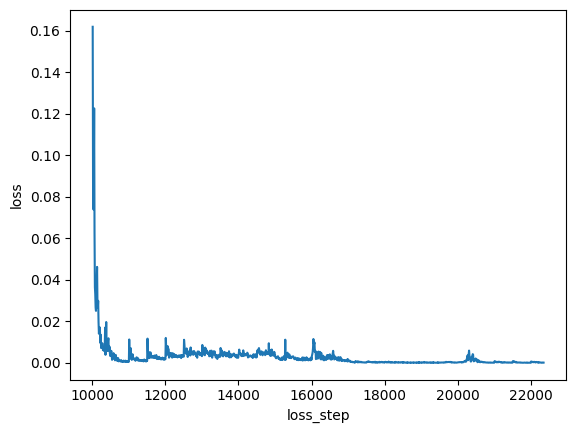

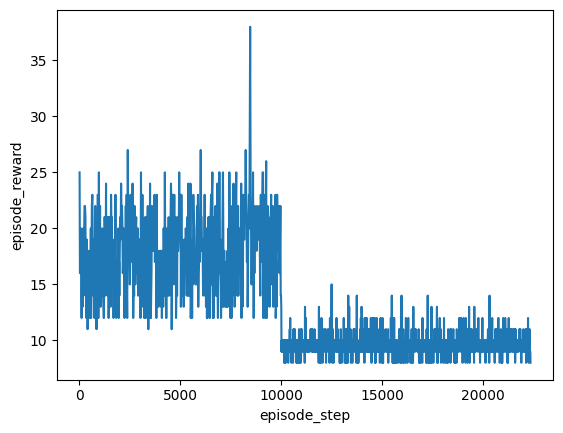

In [12]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(history_dict['loss_step'], history_dict['loss'])
plt.xlabel('loss_step')
plt.ylabel('loss')

plt.figure()
plt.plot(history_dict['episode_step'], history_dict['episode_reward'])
plt.xlabel('episode_step')
plt.ylabel('episode_reward')

In [ ]:
###
# Evaluate the model.
###
env = config.gym.make()
env = gym.wrappers.RecordEpisodeStatistics(env) # Track statistics for every episode.
env = gym.wrappers.Autoreset(env) # Automatically reset the environment (continuous training).
observation, _ = env.reset() # Reset the environment.
for t in range(config.total_timesteps):
    pmfs = config.model_policy(observation)
    action = jnp.argmax(pmfs, axis=-1).item()
    print(f"{action = }")
    next_observation, reward, done, truncation, info = env.step(action)
    if done:
        break
    
    # Update current observation with next observation.
    observation = next_observation.copy()
    
nnx.display(info)

pmfs.shape = (1, 2)
0
pmfs.shape = (1, 2)
0
pmfs.shape = (1, 2)
0
pmfs.shape = (1, 2)
0
pmfs.shape = (1, 2)
0
pmfs.shape = (1, 2)
0
pmfs.shape = (1, 2)
0
pmfs.shape = (1, 2)
0
pmfs.shape = (1, 2)
0


----

# OLD debugging

In [34]:
batch_size = 128
# num_actions = 5
# num_actions = 3
num_actions = 4
din = 4
# n_reuploads = 3
n_reuploads = 2
m_moment = 1

In [35]:
# model = qnrl.modules.QuantumNativeQNetwork(
model_policy = qnrl.modules.QuantumNativeQNetworkCascade(
    diff_method="backprop",
    # diff_method=None,
    # shots=100,
    shots=None,
    din=din,
    n_actions = num_actions,
    n_returns=101, # 101
    # n_returns=2**7, # 101
    # n_returns=2**3, # 101
    z_min=-100,
    z_max=100,
    m_moment=m_moment,
    n_reuploads=n_reuploads,
    # n_reuploads=1,
    n_layers=5,
    rngs_kwargs=dict(default=0),
)
model_target = qnrl.modules.QuantumNativeQNetworkCascade(
    diff_method="backprop",
    # diff_method=None,
    # shots=100,
    shots=None,
    din=din,
    n_actions = num_actions,
    n_returns=101, # 101
    # n_returns=2**7, # 101
    # n_returns=2**3, # 101
    z_min=-100,
    z_max=100,
    m_moment=m_moment,
    n_reuploads=n_reuploads,
    # n_reuploads=1,
    n_layers=5,
    rngs_kwargs=dict(default=42),
)


nnx.display(model_policy)
# nnx.display(model.returns_probs_matrix.sum(axis=-1))

In [36]:
# Create optimizer for model.
tx = optax.adam(learning_rate=1e-3)
optimizer = nnx.Optimizer(model_policy, tx, wrt=nnx.Param)

In [37]:
key = jax.random.PRNGKey(0)
key, subkey = jax.random.split(key)
observations = jax.random.uniform(subkey, shape=(1,din,)) # Single observation for circuit drawing.

print(qml.draw(model_policy.circuit)(
    inputs=observations,
    weights=model_policy.circ_weights,
    # weights=model_policy.circ_weights[0],
    n_actions=model_policy.n_actions,
    d_actions=model_policy.d_actions,
    d_returns=model_policy.d_returns,
    m_moment=model_policy.m_moment,
    # n_reuploads=model_policy.n_reuploads,
    probs_actions=jnp.ones(shape=(model_policy.n_actions,)),
    n_layers=model_policy.n_layers,
    U_atoms=model_policy.U_atoms,
))

0: ─╭|Ψ⟩ ···
1: ─╰|Ψ⟩ ···
2: ───── ···
3: ───── ···
4: ───── ···
5: ───── ···
6: ───── ···
7: ───── ···
8: ───── ···

0: ··· ─╭Select(1.10,0.42,0.57,1.10,0.42,0.57,1.10,0.42,0.57,1.97,0.38,2.09,0.49,0.60,2.21,0.18,1.01,1.10,2.39,0.81,1.89,0.08,0.08,0.08,0.08,0.08,0.08,0.08,1.10,0.42,0.57,1.10,0.42,0.57,1.10,0.42,0.57,1.97,0.38,2.09,0.49,0.60,2.21,0.18,1.01,1.10,2.39,0.81,1.89,0.08,0.08,0.08,0.08,0.08,0.08,0.08,0.82,2.68,0.78,0.82,2.68,0.78,0.82,2.68,0.78,0.40,2.83,1.83,2.25,2.76,2.83,1.59,2.44,2.74,2.57,2.32,0.66,0.08,0.08,0.08,0.08,0.08,0.08,0.08,2.68,1.96,0.86,2.68,1.96,0.86,2.68,1.96,0.86,1.84,2.46,0.03,1.44,1.28,1.54,0.25,0.74,3.01,0.74,1.81,1.28,0.08,0.08,0.08,0.08,0.08,0.08,0.08,1.82,1.88,2.01,1.82,1.88,2.01,1.82,1.88,2.01,1.86,0.33,1.00,1.35,2.64,2.40,1.13,1.15,1.19,2.35,2.23,0.37,0.08,0.08,0.08,0.08,0.08,0.08,0.08,0.16,2.91,2.40,0.16,2.91,2.40,0.16,2.91,2.40,1.10,2.61,2.42,1.17,0.56,2.49,2.64,3.00,1.93,0.18,1.01,1.65,0.11,1.50,1.74,0.11,1.50,1.74,0.11,1.50,1.74,3.06,0.98,1.82,0

In [38]:
# Pre-compile a single observation variant.
key, subkey = jax.random.split(key)
probs_actions = model_policy(jax.random.uniform(subkey, shape=(1,din,)))
best_actions = probs_actions.argmax(axis=-1)
print(f"{probs_actions=}")
print(f"{best_actions=}")

probs_actions=Array([[7.28900476e-02, 8.16291717e-04, 6.93318233e-02, 8.56961837e-01]],      dtype=float64)
best_actions=Array([3], dtype=int64)


In [39]:
orig = jnp.array([0.05, 0.17, 0.06, 0.2 , 0.52])

In [40]:
orig = jnp.array([0.00038063, 0.00252366, 0.00067597, 0.00498676, 0.00739645])
orig / orig.sum()

Array([0.02384381, 0.15808969, 0.0423448 , 0.31238572, 0.46333598],      dtype=float64)

In [41]:
# Generate a batched observation.
key, subkey = jax.random.split(key)
observations = jax.random.uniform(subkey, shape=(batch_size,din,))

In [42]:
probs_actions = model_policy(observations)

In [43]:
best_actions = probs_actions.argmax(axis=-1)
best_actions
# nnx.display(best_actions)

Array([2, 2, 2, 2, 3, 2, 2, 3, 2, 3, 2, 2, 3, 3, 3, 2, 2, 2, 3, 1, 3, 1,
       3, 1, 2, 3, 3, 2, 3, 3, 3, 1, 3, 2, 2, 3, 3, 2, 1, 2, 2, 2, 3, 2,
       2, 3, 2, 2, 2, 2, 2, 3, 3, 2, 3, 3, 2, 3, 1, 3, 2, 1, 1, 3, 3, 3,
       3, 2, 2, 3, 3, 3, 2, 1, 1, 1, 3, 1, 1, 1, 2, 2, 3, 1, 3, 3, 3, 3,
       2, 3, 3, 2, 2, 3, 2, 2, 1, 2, 2, 3, 3, 3, 3, 2, 2, 3, 2, 3, 3, 2,
       3, 1, 3, 2, 1, 3, 2, 2, 2, 3, 1, 2, 3, 3, 2, 2, 1, 3], dtype=int64)

In [44]:
nnx.display(probs_actions.T)

In [45]:
nnx.display(probs_actions[:, jnp.array(model_policy.active_action_idx, dtype=int)].T)

In [46]:
nnx.display(nnx.softmax(probs_actions[:, jnp.array(model_policy.active_action_idx, dtype=int)], axis=-1).T)

In [47]:
nnx.display((probs_actions / probs_actions.sum(axis=-1, keepdims=True)).T)

In [48]:
probs_actions.sum(axis=-1, keepdims=True).shape

(128, 1)

------

# Try computing loss.

In [49]:
@nnx.jit
def update(model_policy, model_target, optimizer, observations):
    
    target_action_probs = model_target(observations)

    def loss_fn(model, x, y):
        y_hat = model(x) # (batch, n_actions), Probability distribution over the actions.
        # batch_idx = jnp.arange(x.shape[0])
        # y_hat = y_hat[batch_idx, selected_actions.squeeze()] # (batch_size,)
        y_hat = jnp.log(y_hat)
        loss = optax.kl_divergence(log_predictions=y_hat, targets=y)
        return loss.mean()

    loss, grads = nnx.value_and_grad(loss_fn)(model=model_policy, x=observations, y=target_action_probs)
    optimizer.update(model_policy, grads)

    return loss

In [53]:
# Generate a batched observation.
key, subkey = jax.random.split(key)
observations = jax.random.uniform(subkey, shape=(batch_size,din,))
# key, subkey = jax.random.split(key)
# target_action_probs = jax.random.uniform(subkey, shape=(batch_size,num_actions,))
# target_action_probs = target_action_probs / target_action_probs.sum(axis=-1, keepdims=True)

loss = update(model_policy=model_policy, model_target=model_target, optimizer=optimizer, observations=observations)

In [54]:
loss

Array(1.44944829, dtype=float64)

In [55]:
# grads